In [1]:
import pandas as pd
import numpy as np
import cv2
import os
import random
import matplotlib.pyplot as plt

In [2]:
GERD= r"D:\AI BIOMEDICAL PROJECT\data\kvasir-dataset-v2\kvasir-dataset-v2"
CATAGORIES= ['dyed-lifted-polyps','dyed-resection-margins','esophagitis','normal-cecum','normal-pylorus','normal-z-line','polyps','ulcerative-colitis']

In [3]:
data=[]

for categories in CATAGORIES:
    pd=os.path.join(GERD,categories)
    label=CATAGORIES.index(categories)
    
    for img in os.listdir(pd):
        img=os.path.join(pd,img)
        img_arr=cv2.imread(img)
        img_arr= cv2.resize(img_arr,(100,100))
        data.append((img_arr,label))

In [4]:
data

[(array([[[2, 4, 4],
          [4, 4, 4],
          [4, 4, 4],
          ...,
          [3, 4, 4],
          [4, 4, 4],
          [2, 4, 4]],
  
         [[3, 3, 3],
          [3, 3, 3],
          [2, 2, 2],
          ...,
          [3, 4, 2],
          [3, 3, 3],
          [1, 3, 3]],
  
         [[3, 3, 3],
          [3, 3, 3],
          [3, 3, 3],
          ...,
          [3, 3, 3],
          [3, 3, 3],
          [1, 3, 3]],
  
         ...,
  
         [[0, 0, 0],
          [1, 1, 1],
          [0, 0, 0],
          ...,
          [0, 0, 0],
          [0, 0, 0],
          [0, 0, 0]],
  
         [[1, 1, 1],
          [1, 1, 1],
          [1, 1, 1],
          ...,
          [1, 1, 1],
          [1, 1, 1],
          [1, 1, 1]],
  
         [[1, 1, 1],
          [1, 1, 1],
          [1, 1, 1],
          ...,
          [1, 1, 1],
          [1, 1, 1],
          [1, 1, 1]]], dtype=uint8),
  0),
 (array([[[5, 5, 5],
          [5, 5, 5],
          [1, 3, 3],
          ...,
          [3, 4, 

In [5]:
random.shuffle(data)

In [6]:
x=[]
y=[]

for features,label in data:
    x.append(features)
    y.append(label)

In [7]:
x=np.array(x)
y=np.array(y)

In [8]:
x

array([[[[ 6,  6,  6],
         [ 6,  6,  6],
         [ 5,  5,  5],
         ...,
         [ 2,  4,  3],
         [ 5,  5,  5],
         [ 5,  5,  5]],

        [[ 4,  6,  6],
         [ 5,  5,  5],
         [ 3,  4,  4],
         ...,
         [ 3,  5,  5],
         [ 6,  4,  4],
         [ 4,  4,  4]],

        [[ 5,  5,  5],
         [ 5,  5,  5],
         [ 4,  5,  5],
         ...,
         [ 2,  4,  4],
         [ 5,  5,  5],
         [ 5,  5,  5]],

        ...,

        [[ 1,  3,  3],
         [ 1,  3,  3],
         [ 2,  3,  3],
         ...,
         [ 0,  2,  2],
         [ 1,  3,  3],
         [ 0,  2,  2]],

        [[ 3,  3,  3],
         [ 3,  3,  3],
         [ 3,  4,  4],
         ...,
         [ 3,  3,  3],
         [ 0,  4,  3],
         [ 2,  2,  2]],

        [[ 3,  3,  3],
         [ 3,  3,  3],
         [ 4,  4,  4],
         ...,
         [ 1,  3,  3],
         [ 3,  3,  3],
         [ 3,  3,  3]]],


       [[[15, 15, 15],
         [15, 15, 15],
         [15, 

In [9]:
x=x/255

In [10]:
x

array([[[[0.02352941, 0.02352941, 0.02352941],
         [0.02352941, 0.02352941, 0.02352941],
         [0.01960784, 0.01960784, 0.01960784],
         ...,
         [0.00784314, 0.01568627, 0.01176471],
         [0.01960784, 0.01960784, 0.01960784],
         [0.01960784, 0.01960784, 0.01960784]],

        [[0.01568627, 0.02352941, 0.02352941],
         [0.01960784, 0.01960784, 0.01960784],
         [0.01176471, 0.01568627, 0.01568627],
         ...,
         [0.01176471, 0.01960784, 0.01960784],
         [0.02352941, 0.01568627, 0.01568627],
         [0.01568627, 0.01568627, 0.01568627]],

        [[0.01960784, 0.01960784, 0.01960784],
         [0.01960784, 0.01960784, 0.01960784],
         [0.01568627, 0.01960784, 0.01960784],
         ...,
         [0.00784314, 0.01568627, 0.01568627],
         [0.01960784, 0.01960784, 0.01960784],
         [0.01960784, 0.01960784, 0.01960784]],

        ...,

        [[0.00392157, 0.01176471, 0.01176471],
         [0.00392157, 0.01176471, 0.01176471]

In [11]:
x.shape

(8000, 100, 100, 3)

In [12]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image
from tensorflow.keras.layers import Conv2D,MaxPooling2D,Flatten,Dense,Activation

In [13]:
model=Sequential()

#Convolutional layers
model.add(Conv2D(32,(3,3),input_shape=x.shape[1:],activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))

model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

#flatten layer
model.add(Flatten())

#Dense layers
model.add(Dense(256, activation='relu'))
model.add(Dense(128, activation='relu'))

#output layers
model.add(Dense(2,activation='softmax'))


C:\Users\HP\anaconda3\lib\site-packages\keras\src\layers\convolutional\base_conv.py:99: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(


In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

model = Sequential()

# Convolutional layers
model.add(Conv2D(32, (3, 3), input_shape=x.shape[1:], activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Flatten layer
model.add(Flatten())

# Dense layers
model.add(Dense(256, activation='relu'))
model.add(Dense(128, activation='relu'))

# Output layer
num_classes = len(categories)  # Number of classes in your dataset
model.add(Dense(num_classes, activation='softmax'))


In [15]:
# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


In [16]:
model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])


In [17]:
history=model.fit(x, y, epochs=10, validation_split=0.1)


Epoch 1/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 48s 197ms/step - accuracy: 0.4614 - loss: 1.3014 - val_accuracy: 0.7025 - val_loss: 0.6477
Epoch 2/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 126s 563ms/step - accuracy: 0.7060 - loss: 0.6585 - val_accuracy: 0.6938 - val_loss: 0.7272
Epoch 3/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 143s 561ms/step - accuracy: 0.7298 - loss: 0.5947 - val_accuracy: 0.7200 - val_loss: 0.6037
Epoch 4/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 127s 565ms/step - accuracy: 0.7586 - loss: 0.5342 - val_accuracy: 0.7563 - val_loss: 0.5562
Epoch 5/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 142s 564ms/step - accuracy: 0.7969 - loss: 0.4764 - val_accuracy: 0.7625 - val_loss: 0.5342
Epoch 6/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 143s 565ms/step - accuracy: 0.7973 - loss: 0.4490 - val_accuracy: 0.7487 - val_loss: 0.5754
Epoch 7/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 140s 558ms/step - accuracy: 0.8199 - loss: 0.4130 - val_accuracy: 0.7912 - val_loss: 0.5250
Epoch 8/10
225/225 ━━━━━━━━━━━━━━━━━━━━ 125s 555ms/step - accuracy: 0.8429 - 

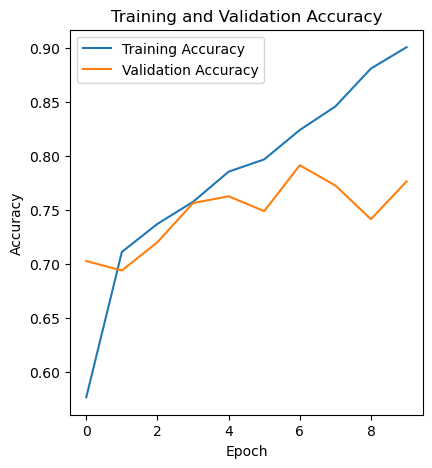

In [18]:
# Visualize training and validation accuracy over epochs
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()


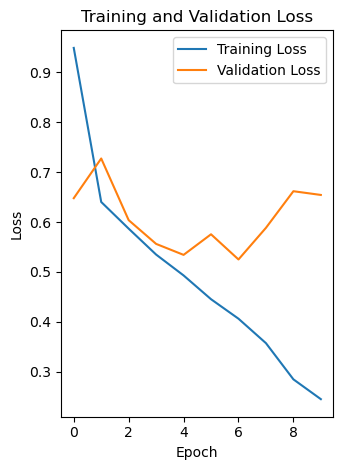

In [19]:
# Visualize training and validation loss over epochs
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [20]:
from keras.preprocessing import image
from tensorflow.keras.applications.vgg16 import preprocess_input


In [21]:
from tensorflow.keras.preprocessing import image
import numpy as np

def predict_from_user_input(model):
    user_image_path = input("Enter the path of an image file: ")
    user_image_path = user_image_path.strip('\"')  # Remove double quotes

    img_pred = image.load_img(user_image_path, target_size=(100, 100))
    img_pred = image.img_to_array(img_pred)
    img_pred = np.expand_dims(img_pred, axis=0)

    rslt = model.predict(img_pred)

    print("Model Output:", rslt)

    # Get the index of the class with the highest probability
    predicted_class_index = np.argmax(rslt)

    # Define your class labels based on your dataset
    class_labels = ["class1", "class2", "class3", "class4", "class5", "class6", "class7", "class8"]

    # Get the predicted class label
    prediction = class_labels[predicted_class_index]

    print("Prediction:", prediction)

# Usage:
predict_from_user_input(model)


Enter the path of an image file: "D:\AI BIOMEDICAL PROJECT\data\kvasir-dataset-v2\kvasir-dataset-v2\normal-cecum\00b99f19-2c31-4c7c-931a-4c3b38d70d1a.jpg"
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 267ms/step
Model Output: [[0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]
Prediction: class2


In [22]:
def predict_from_user_input(model):
    user_image_path = input("Enter the path of an image file: ")
    user_image_path = user_image_path.strip('\"')  # Remove double quotes

    img_pred = image.load_img(user_image_path, target_size=(100, 100))
    img_pred = image.img_to_array(img_pred)
    img_pred = np.expand_dims(img_pred, axis=0)

    rslt = model.predict(img_pred)

    print("Model Output:", rslt)

    if rslt[0][0] > rslt[0][1]:
        prediction = "GERD"
    else:
        prediction = "NO GERD"

    print("Prediction:", prediction)

In [23]:
# Call the function with your model
predict_from_user_input(model)

Enter the path of an image file: "D:\AI BIOMEDICAL PROJECT\data\kvasir-dataset-v2\kvasir-dataset-v2\normal-cecum\00b99f19-2c31-4c7c-931a-4c3b38d70d1a.jpg"
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
Model Output: [[0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]
Prediction: NO GERD


In [24]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ Layer (type)                       ┃ Output Shape                  ┃     Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)                  │ (None, 98, 98, 32)            │         896 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ max_pooling2d_3 (MaxPooling2D)     │ (None, 49, 49, 32)            │           0 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ conv2d_4 (Conv2D)                  │ (None, 47, 47, 64)            │      18,496 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ max_pooling2d_4 (MaxPooling2D)     │ (None, 23, 23, 64)            │           0 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ conv2d_5 (Conv2D)                  │ (None, 21, 21, 128)           │      73,856 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ max_pooling2d_5 (MaxPooling2D)     │ (None, 10, 10, 128)           │           0 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ flatten_1 (Flatten)                │ (None, 12800)                 │           0 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ dense_3 (Dense)                    │ (None, 256)                   │   3,277,056 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ dense_4 (Dense)                    │ (None, 128)                   │      32,896 │
├────────────────────────────────────┼───────────────────────────────┼─────────────┤
│ dense_5 (Dense)                    │ (None, 18)                    │       2,322 │
└────────────────────────────────────┴───────────────────────────────┴─────────────┘

 Total params: 10,216,568 (38.97 MB)

 Trainable params: 3,405,522 (12.99 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,811,046 (25.98 MB)